# 00 · Quickstart

Open the files with plain xarray, choose an event and a link, and plot them next to the nearest rain gauge.
Everything is chosen on the netCDF itself, as in the OpenSense examples: `sel(time=slice(...))` for the event and
`sel(cml_id=...)` for a path; a condition such as `links.frequency > 50_000` picks a group of paths.
Only the network overview in section 2 uses the repo's `analysis.v2` helpers.
Set the next cell, then run all cells.

In [1]:
# ---- choose ----
EVENT = "2024-03-23"        # a day (UTC); the table below lists the 10 radar days (5 rain, 5 snow)
DAYS_BEFORE = 1             # days shown before the event day
DAYS_AFTER = 2              # days shown after it
CML = "7"                   # a path (cml_id), "1" to "372"

In [2]:
import os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xarray as xr

# The record in dataset/raw/openmesh_v2/ (or OPENMESH_V2_DIR), downloaded from Zenodo on first run.
sys.path.insert(0, str(Path("../..").resolve() / "src"))
from analysis import v2 as om
DATA = om.setup()
links = xr.open_dataset(DATA / "data" / "links" / "openmesh_links.nc")

START = pd.Timestamp(EVENT) - pd.Timedelta(days=DAYS_BEFORE)
END = pd.Timestamp(EVENT) + pd.Timedelta(days=DAYS_AFTER)


n_sublinks = int(links.frequency.notnull().sum())        # sublinks in use have a frequency
first_day, last_day = str(links.time.values[0])[:10], str(links.time.values[-1])[:10]
print(f"{links.sizes['cml_id']} paths, {n_sublinks} sublinks, {links.sizes['time']:,} time stamps, "
      f"{first_day} to {last_day} UTC")

radar_days = pd.read_csv(DATA / "data" / "weather" / "radar" / "radar_events.csv")
radar_days[["kind", "day", "asos_median_mm", "radar_mean_mm"]]

372 paths, 758 sublinks, 475,518 time stamps, 2023-10-29 to 2026-11-01 UTC


,kind,day,asos_median_mm,radar_mean_mm
0,rain,2023-11-22,39.12,38.3
1,rain,2023-12-18,69.34,66.4
2,rain,2024-03-10,36.07,34.3
3,rain,2024-03-23,85.85,72.0
4,rain,2025-10-30,45.97,49.5
5,snow,2024-02-13,16.51,17.3
6,snow,2025-12-14,13.21,13.8
7,snow,2025-12-27,8.76,9.4
8,snow,2026-01-25,20.96,30.2
9,snow,2026-02-23,9.40,43.2


## 1. The links file

* `cml_id`: a path between two NYC Mesh buildings. `sublink_id`: a frequency and a direction on it, two per
  frequency; `sublink_1` is the path's highest frequency. Seven paths are dual-frequency (`sublink_3`, `sublink_4` at
  5 GHz). `frequency` (MHz) is given per path and sublink, `length` (m) per path.
* `time`: the stamps the network stored, one per minute to 2025-04-21 (only 00–01 UTC each day from 2024-07-15),
  then one per poll.
* `rsl` (instantaneous) up to 2025-04-21; after that `rsl_avg` and `rsl_max` over the window that ends at each stamp.
  `rsl.fillna(rsl_avg)` gives one level over the whole record.

In [3]:
rows = []
for name in ["rsl", "rsl_avg", "rsl_max", "frequency", "length"]:
    var = links[name]
    rows.append({"variable": name, "long name": var.attrs.get("long_name", ""), "units": var.attrs.get("units", ""),
                 "dimensions": " x ".join(var.dims)})
pd.DataFrame(rows).set_index("variable")

,long name,units,dimensions
variable,,,
rsl,received_signal_level,dBm,cml_id x sublink_id x time
rsl_avg,averaged_received_signal_level_over_time_window,dBm,cml_id x sublink_id x time
rsl_max,maximum_received_signal_level_over_time_window,dBm,cml_id x sublink_id x time
frequency,sublink_frequency,MHz,cml_id x sublink_id
length,distance_between_pair_of_antennas,m,cml_id


## 2. The network

Per band: paths, sublinks, channels and lengths.

In [4]:
om.plots.network_table(om.link_meta())

,directional links,paths,f min (GHz),f max (GHz),sites,median length (m),shortest (m),longest (m),paths with another band
V60 upper (64–70 GHz),58,30,64.80,69.12,37,1288,397,4352,6
V60 lower (58–63 GHz),8,4,58.32,62.64,7,971,624,1284,1
K24 (24 GHz),14,7,24.10,24.20,11,3609,1401,4426,2
C5 (5–6 GHz),678,339,5.29,5.82,364,706,37,4479,7


Where the paths are (the chosen one in black) and what they carry.

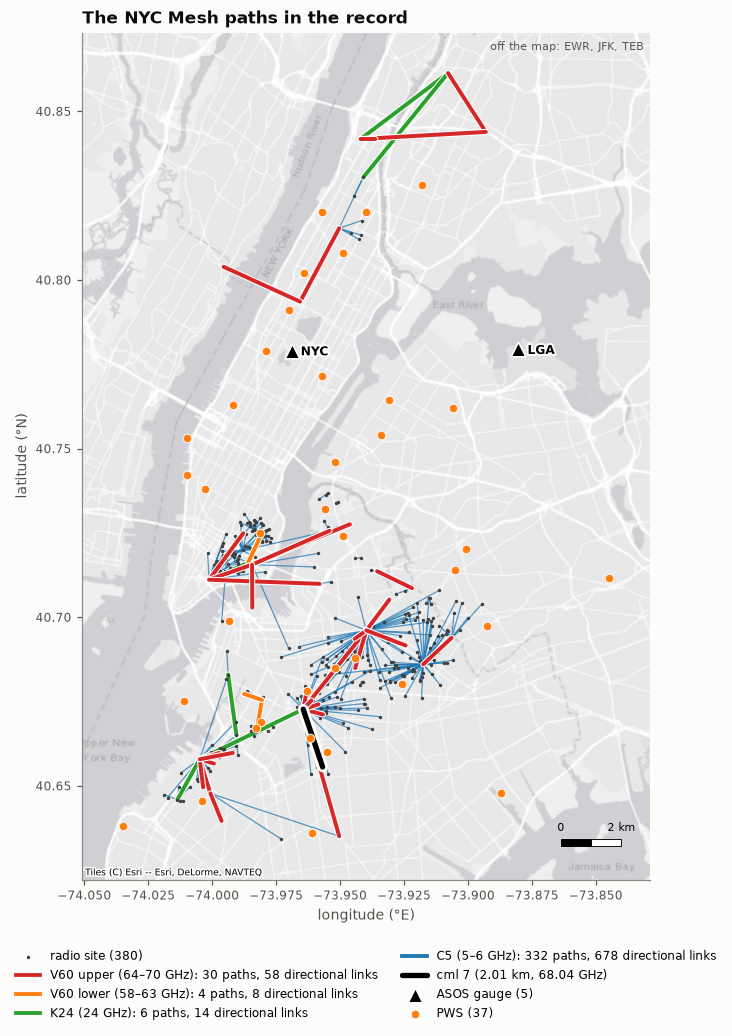

<Axes: title={'left': 'The NYC Mesh paths in the record'}, xlabel='longitude (°E)', ylabel='latitude (°N)'>

In [5]:
om.plots.network_map(om.link_meta(), highlight=CML)

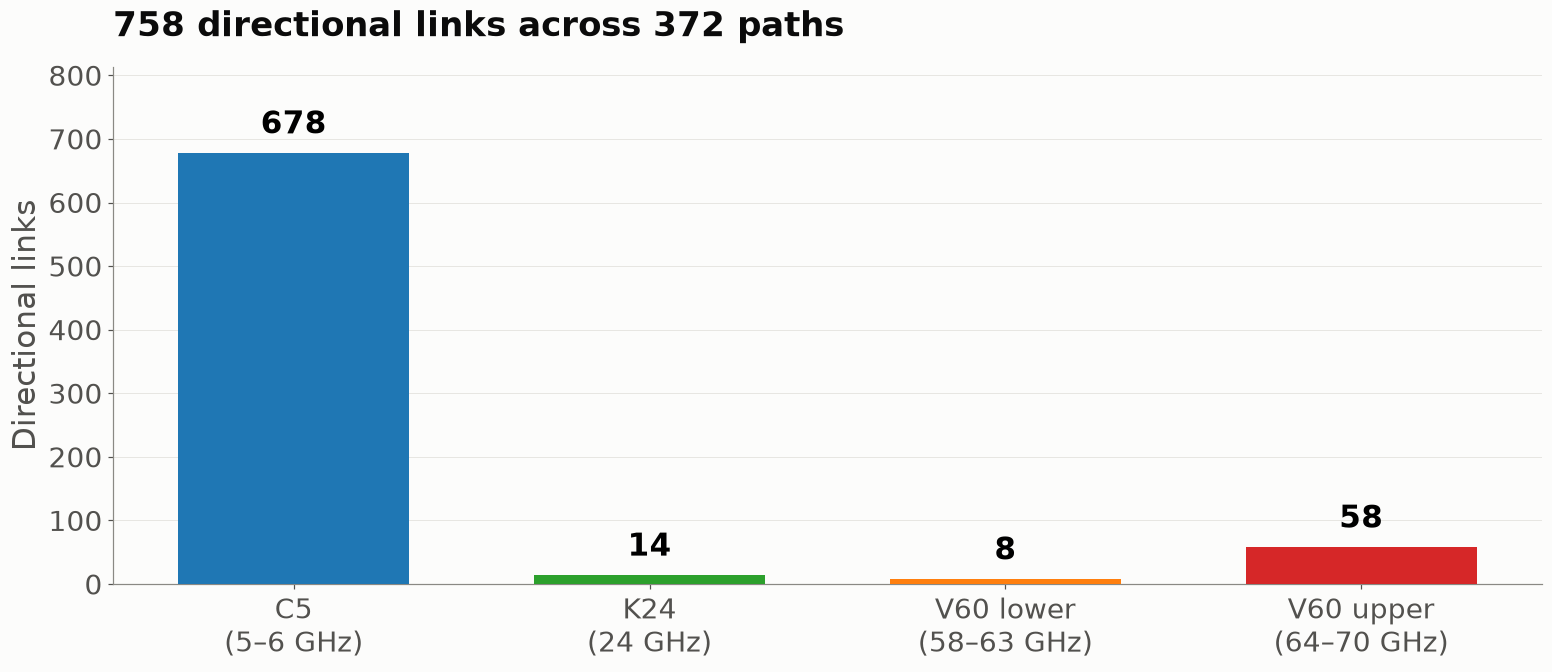

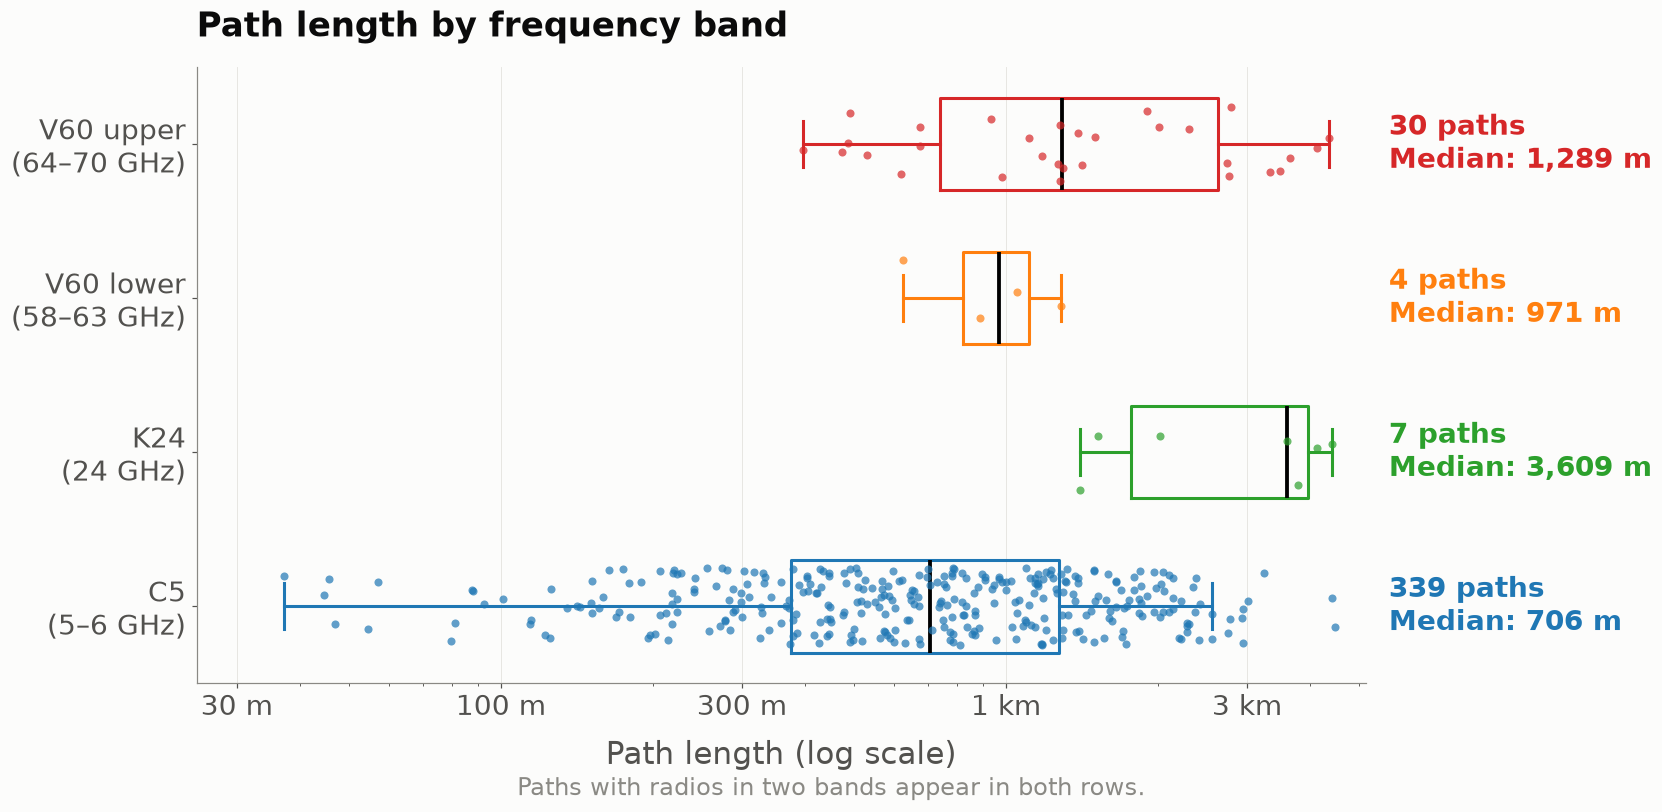

(<Figure size 1540x660 with 1 Axes>, <Figure size 1650x770 with 1 Axes>)

In [6]:
om.plots.link_features(om.link_meta())

## 3. The chosen link around the event

`links.sel(cml_id=CML, time=slice(START, END))`: every sublink of the path; dots are the stored values, the line the
hourly mean. Grey: the event day.

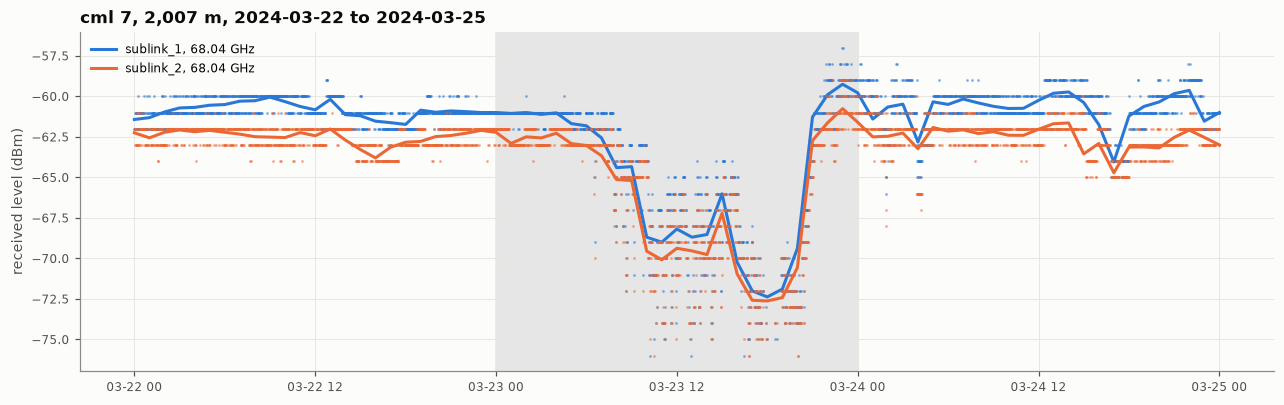

In [7]:
path = links.sel(cml_id=CML, time=slice(START, END))
level = path.rsl.fillna(path.rsl_avg)                   # one level: rsl to 2025-04-21, rsl_avg after

# The sublinks this path uses: the ones with a frequency (the others are empty slots)
used_sublinks = [s for s in path.sublink_id.values if np.isfinite(float(path.frequency.sel(sublink_id=s)))]

fig, ax = plt.subplots(figsize=(14, 4))
for sublink in used_sublinks:
    values = level.sel(sublink_id=sublink)
    hourly_mean = values.resample(time="1h").mean()
    ghz = float(path.frequency.sel(sublink_id=sublink)) / 1000
    dots, = ax.plot(values.time, values, ".", markersize=2, alpha=0.4)
    ax.plot(hourly_mean.time, hourly_mean, color=dots.get_color(), label=f"{sublink}, {ghz:.2f} GHz")

event_start = pd.Timestamp(EVENT)
ax.axvspan(event_start, event_start + pd.Timedelta("1D"), color="0.9", zorder=0)   # the event day in grey
ax.set_ylabel("received level (dBm)")
ax.set_title(f"cml {CML}, {float(path.length):,.0f} m, {START:%Y-%m-%d} to {END:%Y-%m-%d}")
ax.legend()
plt.show()

## 4. Any path, sublink by sublink

Set `ONE` to any `cml_id`: one panel per sublink (frequency and direction), with every signal the file holds there.

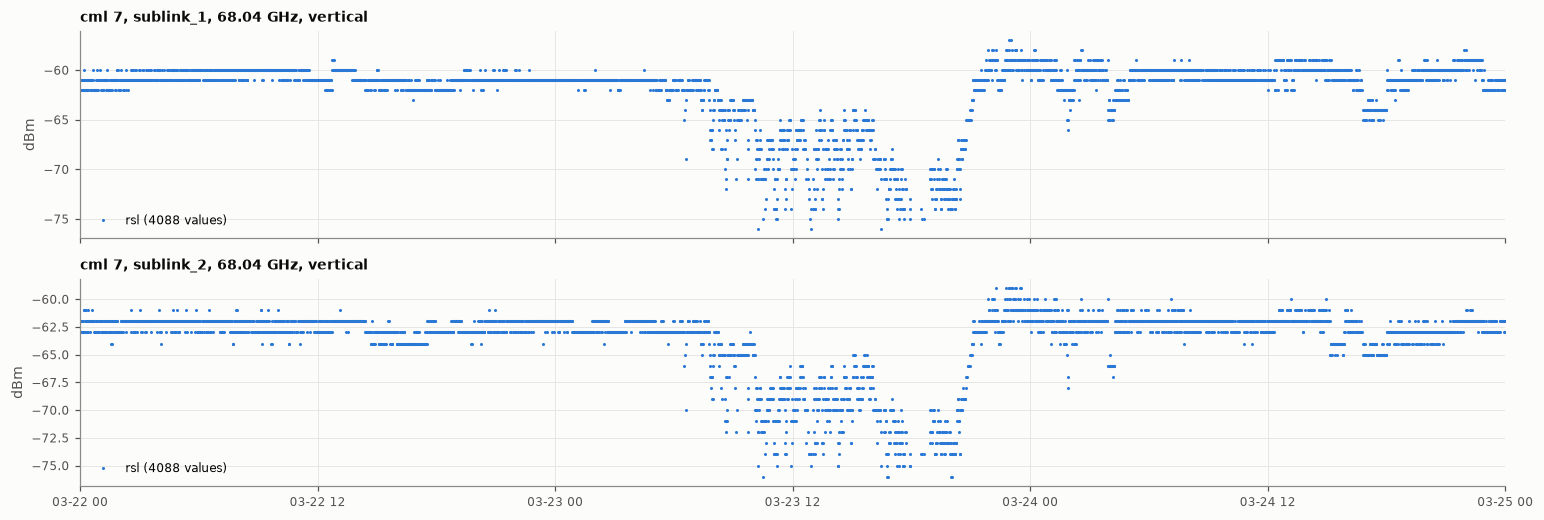

In [8]:
ONE = CML                       # any path, e.g. "8" (dual-frequency: 60 and 5 GHz)

one_path = links.sel(cml_id=ONE, time=slice(START, END))
sublinks = [s for s in one_path.sublink_id.values if np.isfinite(float(one_path.frequency.sel(sublink_id=s)))]

fig, axes = plt.subplots(len(sublinks), 1, figsize=(14, 2.4 * len(sublinks)), sharex=True, squeeze=False)
for ax, sublink in zip(axes[:, 0], sublinks):
    one = one_path.sel(sublink_id=sublink)
    for signal in ["rsl", "rsl_avg", "rsl_max"]:            # every signal the file holds for this sublink
        n_values = int(one[signal].notnull().sum())
        if n_values > 0:
            ax.plot(one.time, one[signal], ".", markersize=2, label=f"{signal} ({n_values} values)")
    ghz = float(one.frequency) / 1000
    ax.set_title(f"cml {ONE}, {sublink}, {ghz:.2f} GHz, {one.polarization.values}", loc="left", fontsize=9)
    ax.set_ylabel("dBm")
    ax.legend(fontsize=8, loc="lower left")
ax.set_xlim(START, END)
plt.tight_layout(); plt.show()

## 5. Rain at the nearest ASOS gauge

`rainfall_amount` where `rainfall_flag == 0`. The gauges are often several km from a link.

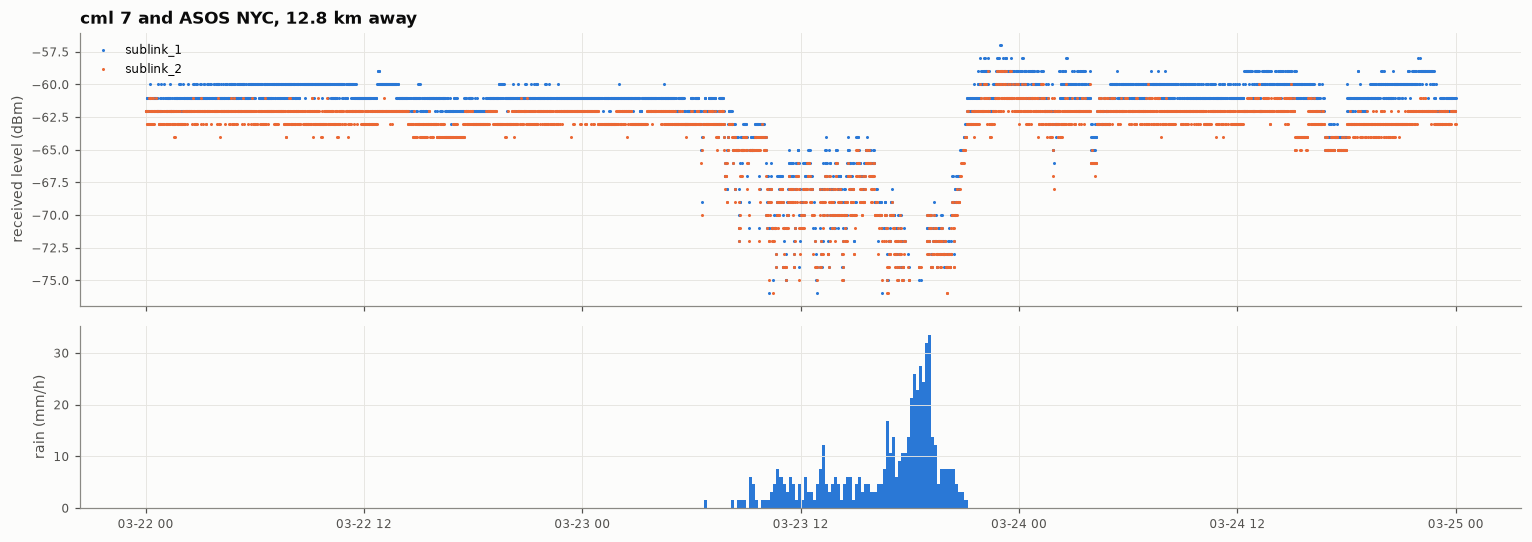

In [9]:
# The ASOS gauge nearest to the middle of the chosen path
asos = xr.open_dataset(DATA / "data" / "weather" / "asos" / "openmesh_asos.nc")
path_lat = float(path.site_0_lat + path.site_1_lat) / 2
path_lon = float(path.site_0_lon + path.site_1_lon) / 2
km_per_degree = 111.0                                   # one degree of latitude; longitude shrinks with cos(latitude)
distance_km = km_per_degree * np.hypot(asos.lat - path_lat, (asos.lon - path_lon) * np.cos(np.radians(path_lat)))
station = str(distance_km.idxmin("id").values)
gauge = asos.sel(id=station, time=slice(START, END))

# Rain rate in mm/h: only the usable minutes (rainfall_flag == 0), summed per 10 minutes.
# A 10-minute step with fewer than 5 usable minutes stays empty instead of counting as 0.
# Each step is labelled by its end, as the minutes are (closed and labelled on the right).
rain_mm = gauge.rainfall_amount.where(gauge.rainfall_flag == 0)
rain_per_10min = rain_mm.resample(time="10min", closed="right", label="right").sum(min_count=5)
rain_rate = rain_per_10min * 6                          # six 10-minute steps per hour

# Plot: the link's received level on top, the gauge's rain below
fig, (ax_link, ax_rain) = plt.subplots(2, 1, figsize=(14, 5), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))
for sublink in used_sublinks:
    ax_link.plot(level.time, level.sel(sublink_id=sublink), ".", markersize=2, label=sublink)
ax_link.set_ylabel("received level (dBm)")
ax_link.set_title(f"cml {CML} and ASOS {station}, {float(distance_km.min()):.1f} km away")
ax_link.legend()
ax_rain.bar(rain_rate.time, rain_rate, width=-pd.Timedelta("10min"), align="edge")   # bar spans the 10 minutes before its end
ax_rain.set_ylabel("rain (mm/h)")
plt.tight_layout(); plt.show()